# k plus proches voisins avec scikit-learn

Le classifieur des k plus proches voisins (k-NN) n'apprend aucun paramètre : il garde les exemples d'entraînement et, pour un nouveau point, fait voter ses k plus proches voisins. Cette démo le montre sur deux jeux :

- deux demi-lunes en deux dimensions, pour voir le vote, puis l'effet de k sur la frontière ;
- le jeu `wine` (13 mesures chimiques), pour la mise à l'échelle des variables et le réglage de k, de la distance et des poids par validation croisée.

Elle finit par la régression (la moyenne des voisins) et les deux limites du k-NN : le coût de la prédiction et la grande dimension.

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.datasets import load_wine, make_classification, make_moons
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.model_selection import GridSearchCV, cross_validate, train_test_split
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

## Données d'exemple : deux demi-lunes

`make_moons` tire 500 points de deux classes en forme de demi-lunes imbriquées ; `noise=0.3` les fait se chevaucher, si bien qu'aucune frontière ne les sépare sans erreur. 30 % des points sont mis de côté pour le test.

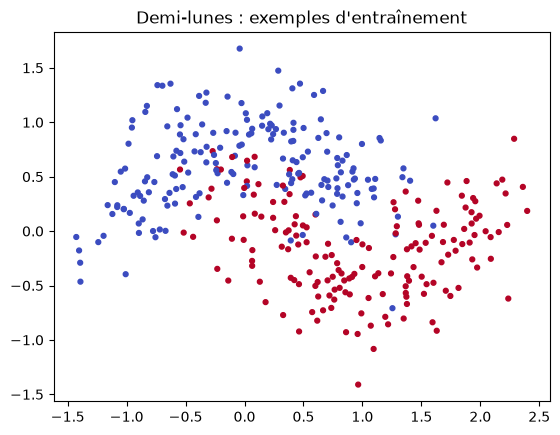

In [2]:
X, y = make_moons(n_samples=500, noise=0.3, random_state=0)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)

plt.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap="coolwarm", s=12)
plt.title("Demi-lunes : exemples d'entraînement")
plt.show()

## Prédire : le vote des voisins

`fit` ne fait que ranger les exemples d'entraînement (dans un arbre qui accélère la recherche des voisins). Pour un nouveau point, `kneighbors` donne ses k plus proches voisins et leurs distances ; `predict` renvoie la classe majoritaire parmi eux, `predict_proba` la part de chaque classe dans le vote.

In [3]:
modele = KNeighborsClassifier(n_neighbors=5)
modele.fit(X_train, y_train)

point = np.array([[0.5, 0.25]])
distances, indices = modele.kneighbors(point)
print("distances des 5 voisins :", distances.round(2))
print("classes des 5 voisins :", y_train[indices])
print("classe prédite :", modele.predict(point))
print("part de chaque classe :", modele.predict_proba(point))

distances des 5 voisins : [[0.08 0.1  0.12 0.13 0.14]]
classes des 5 voisins : [[0 0 0 1 1]]
classe prédite : [0]
part de chaque classe : [[0.6 0.4]]


## Choisir k

k règle le compromis biais-variance. On mesure, pour k de 1 à 200, l'exactitude (*accuracy*) sur l'entraînement et en validation croisée à 5 plis, sur les seuls exemples d'entraînement (le test reste de côté).

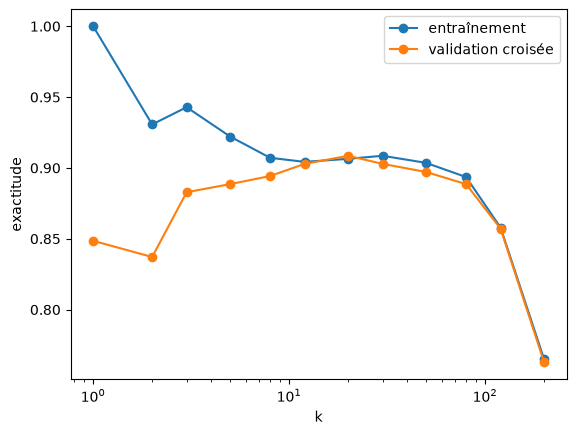

In [4]:
ks = [1, 2, 3, 5, 8, 12, 20, 30, 50, 80, 120, 200]
scores_entrainement, scores_validation = [], []
for k in ks:
  scores = cross_validate(
    KNeighborsClassifier(n_neighbors=k),
    X_train,
    y_train,
    cv=5,
    return_train_score=True,
  )
  scores_entrainement.append(scores["train_score"].mean())
  scores_validation.append(scores["test_score"].mean())

plt.plot(ks, scores_entrainement, "o-", label="entraînement")
plt.plot(ks, scores_validation, "o-", label="validation croisée")
plt.xscale("log")
plt.xlabel("k")
plt.ylabel("exactitude")
plt.legend()
plt.show()

- k = 1 : aucune erreur sur l'entraînement (chaque point est son propre voisin), mais une exactitude en validation bien plus basse : le modèle apprend le bruit (variance forte, surapprentissage).
- k grand (120, 200, sur 280 exemples par pli) : les deux courbes baissent ensemble, la frontière ne suit plus la forme des lunes (biais fort). À la limite, k = n prédit la classe majoritaire partout (avec des poids uniformes, le réglage par défaut).
- Entre les deux, un plateau autour de k = 10 à 50 : c'est là qu'on choisit k.

Les frontières de décision de trois valeurs de k, avec l'exactitude sur le test :

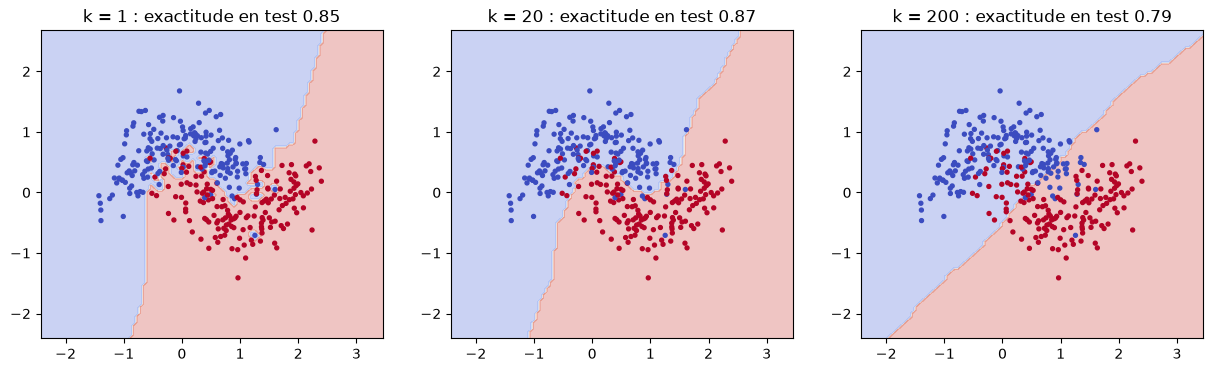

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, k in zip(axes, [1, 20, 200]):
  modele = KNeighborsClassifier(n_neighbors=k).fit(X_train, y_train)
  DecisionBoundaryDisplay.from_estimator(
    modele, X, ax=ax, cmap="coolwarm", alpha=0.3, response_method="predict"
  )
  ax.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap="coolwarm", s=8)
  ax.set_title(f"k = {k} : exactitude en test {modele.score(X_test, y_test):.2f}")
plt.show()

## Mise à l'échelle : le jeu `wine`

`load_wine` (fourni avec scikit-learn) décrit 178 vins d'une même région d'Italie, issus de trois cépages (les classes 0, 1 et 2). Chaque ligne est un vin, chaque colonne une de ses 13 mesures chimiques : alcool, acide malique, magnésium, intensité de la couleur, proline… Ces mesures n'ont pas la même échelle : la proline se compte en centaines, la teinte (`hue`) autour de 1.

In [6]:
vins = load_wine(as_frame=True)
X, y = vins.data, vins.target
print(X.shape, "; vins par classe :", y.value_counts().sort_index().tolist())
X.describe().loc[["mean", "std", "min", "max"]].T.round(2)

(178, 13) ; vins par classe : [59, 71, 48]


,mean,std,min,max
alcohol,13.00,0.81,11.03,14.83
malic_acid,2.34,1.12,0.74,5.80
ash,2.37,0.27,1.36,3.23
alcalinity_of_ash,19.49,3.34,10.60,30.00
magnesium,99.74,14.28,70.00,162.00
total_phenols,2.30,0.63,0.98,3.88
flavanoids,2.03,1.00,0.34,5.08
nonflavanoid_phenols,0.36,0.12,0.13,0.66
proanthocyanins,1.59,0.57,0.41,3.58
color_intensity,5.06,2.32,1.28,13.00


Un quart des vins est mis de côté pour le test, dans les mêmes proportions de classes (`stratify=y`).

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
  X, y, test_size=0.25, stratify=y, random_state=0
)

### Sans mise à l'échelle

Le k-NN sur les mesures brutes, puis, pour le premier vin du test, la part de chaque variable dans la somme des carrés des écarts à ses 5 voisins (le carré de la distance euclidienne).

In [8]:
brut = KNeighborsClassifier(n_neighbors=5).fit(X_train, y_train)
print(f"Exactitude en test, sans mise à l'échelle : {brut.score(X_test, y_test):.3f}")

vin = X_test.iloc[[0]]
_, indices = brut.kneighbors(vin)
carres = (X_train.iloc[indices[0]].to_numpy() - vin.to_numpy()) ** 2
part = pd.Series(carres.sum(axis=0) / carres.sum(), index=X.columns)
part.sort_values(ascending=False).head(3).round(3)

Exactitude en test, sans mise à l'échelle : 0.667


proline            0.677
magnesium          0.204
color_intensity    0.052
dtype: float64

La proline et le magnésium, les deux mesures de plus grande échelle, font l'essentiel de la distance : les voisins sont choisis sur elles, les 11 autres mesures comptent à peine.

### Avec mise à l'échelle

`StandardScaler` centre et réduit chaque variable (moyenne 0, écart-type 1). Dans un pipeline, ses moyennes et écarts-types sont calculés sur les données passées à `fit`, l'entraînement seul, puis appliqués tels quels au test.

In [9]:
standardise = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))
standardise.fit(X_train, y_train)
print(
  f"Exactitude en test, avec mise à l'échelle : {standardise.score(X_test, y_test):.3f}"
)

Exactitude en test, avec mise à l'échelle : 0.933


## Régler k, la distance et les poids

`GridSearchCV` essaie toutes les combinaisons de la grille par validation croisée à 5 plis, sur l'entraînement seul :

- `n_neighbors` : k, de 1 à 30 ;
- `weights` : `"uniform"` (chaque voisin compte pour une voix) ou `"distance"` (voix pondérée par l'inverse de la distance) ;
- `p` : la distance de Minkowski, 1 pour Manhattan, 2 pour euclidienne.

Les paramètres d'une étape d'un pipeline se nomment `<étape>__<paramètre>`.

In [10]:
recherche = GridSearchCV(
  make_pipeline(StandardScaler(), KNeighborsClassifier()),
  {
    "kneighborsclassifier__n_neighbors": list(range(1, 31)),
    "kneighborsclassifier__weights": ["uniform", "distance"],
    "kneighborsclassifier__p": [1, 2],
  },
  cv=5,
)
recherche.fit(X_train, y_train)
print("Meilleurs paramètres :", recherche.best_params_)
print(f"Exactitude en validation croisée : {recherche.best_score_:.3f}")
print(f"Exactitude en test : {recherche.score(X_test, y_test):.3f}")

Meilleurs paramètres : {'kneighborsclassifier__n_neighbors': 4, 'kneighborsclassifier__p': 1, 'kneighborsclassifier__weights': 'distance'}
Exactitude en validation croisée : 0.962
Exactitude en test : 1.000


Le test ne compte que 45 vins : une erreur de plus ou de moins y change l'exactitude de 2 points. C'est la validation croisée qui choisit les paramètres ; le test, gardé à part, ne sert qu'à mesurer le modèle retenu.

## Régression : la moyenne des voisins

`KNeighborsRegressor` prédit la moyenne des cibles des k plus proches voisins. Sur une sinusoïde bruitée, en une dimension, la prédiction est une fonction en escalier : collée au bruit pour k = 1, lisse pour k = 10, aplatie pour k = 50.

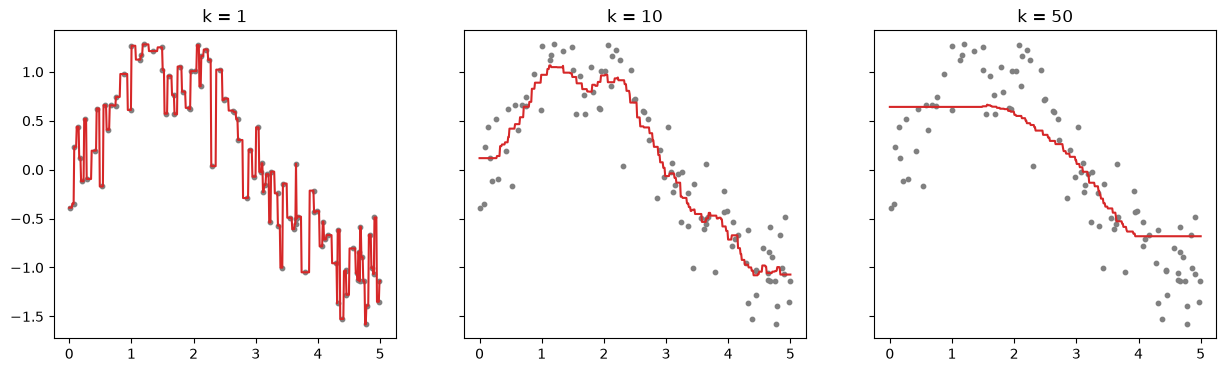

In [11]:
rng = np.random.default_rng(0)
x = np.sort(rng.uniform(0, 5, 100))[:, None]
cible = np.sin(x).ravel() + rng.normal(0, 0.3, 100)
x_grille = np.linspace(0, 5, 500)[:, None]

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, k in zip(axes, [1, 10, 50]):
  regresseur = KNeighborsRegressor(n_neighbors=k).fit(x, cible)
  ax.scatter(x, cible, s=10, color="gray")
  ax.plot(x_grille, regresseur.predict(x_grille), color="C3")
  ax.set_title(f"k = {k}")
plt.show()

## Limites

### Le coût de la prédiction

Entraîner un k-NN, c'est ranger les données ; prédire, c'est calculer la distance du point à chacun des n exemples gardés. Ci-dessous, en force brute (`algorithm="brute"`, toutes les distances calculées), le temps d'entraînement et celui de 1 000 prédictions, pour 20 variables et n de 10 000 à 1 000 000 exemples. Les arbres (k-d, *ball tree*, que l'option par défaut `"auto"` choisit en petite dimension) évitent une partie des calculs, mais de moins en moins quand le nombre de variables augmente.

In [12]:
for n in [10_000, 100_000, 1_000_000]:
  X_n, y_n = make_classification(n_samples=n + 1000, n_features=20, random_state=0)
  modele = KNeighborsClassifier(n_neighbors=5, algorithm="brute")
  debut = time.perf_counter()
  modele.fit(X_n[:n], y_n[:n])
  entraine = time.perf_counter()
  modele.predict(X_n[n:])
  predit = time.perf_counter()
  print(
    f"n = {n:>9_} : entraînement {entraine - debut:.4f} s,"
    f" 1 000 prédictions {predit - entraine:.3f} s"
  )

n =    10_000 : entraînement 0.0021 s, 1 000 prédictions 0.221 s
n =   100_000 : entraînement 0.0161 s, 1 000 prédictions 0.527 s
n = 1_000_000 : entraînement 0.1387 s, 1 000 prédictions 4.576 s


L'entraînement reste presque instantané ; le temps de prédiction croît comme n. Sur de gros volumes, on se tourne vers les voisins approchés (HNSW, FAISS), qui trouvent presque toujours les bons voisins sans calculer toutes les distances.

### La grande dimension

Pour 1 000 points tirés au hasard dans un cube de dimension d, le rapport entre la distance au plus lointain et la distance au plus proche, vus d'un autre point au hasard : grand, le plus proche voisin est bien plus proche que les autres ; proche de 1, tous les points sont presque à la même distance, et « plus proche » ne veut plus dire grand-chose (la malédiction de la dimension).

In [13]:
rng = np.random.default_rng(0)
for d in [2, 10, 100, 1000, 10_000]:
  points = rng.uniform(size=(1000, d))
  distances = np.linalg.norm(points - rng.uniform(size=d), axis=1)
  print(
    f"d = {d:>6} : plus lointain / plus proche = {distances.max() / distances.min():.2f}"
  )

d =      2 : plus lointain / plus proche = 135.62
d =     10 : plus lointain / plus proche = 4.48
d =    100 : plus lointain / plus proche = 1.39
d =   1000 : plus lointain / plus proche = 1.11
d =  10000 : plus lointain / plus proche = 1.04


Des variables inutiles ont le même effet sur un vrai jeu : on ajoute aux 13 mesures de `wine` des colonnes de bruit pur, puis on mesure le k-NN (k = 5, avec mise à l'échelle) par validation croisée. Chaque colonne de bruit pèse autant qu'une vraie mesure dans la distance.

In [14]:
rng = np.random.default_rng(0)
for nb_bruit in [0, 10, 50, 200, 1000]:
  X_bruite = np.hstack([X.to_numpy(), rng.normal(size=(len(X), nb_bruit))])
  modele = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))
  scores = cross_validate(modele, X_bruite, y, cv=5)
  print(
    f"{nb_bruit:>4} colonnes de bruit :"
    f" exactitude en validation croisée {scores['test_score'].mean():.3f}"
  )

   0 colonnes de bruit : exactitude en validation croisée 0.949
  10 colonnes de bruit : exactitude en validation croisée 0.944
  50 colonnes de bruit : exactitude en validation croisée 0.860
 200 colonnes de bruit : exactitude en validation croisée 0.697
1000 colonnes de bruit : exactitude en validation croisée 0.512


Avec 1 000 colonnes de bruit, l'exactitude tombe autour de la moitié, à peine mieux que les 40 % obtenus en prédisant toujours la classe la plus fréquente (71 vins sur 178) : les 13 vraies mesures se noient dans le bruit. Avant un k-NN en grande dimension : sélectionner les variables utiles, ou réduire la dimension (ACP).

## À retenir

- Un k-NN n'apprend rien : il garde les exemples et fait voter (ou moyenne) les k plus proches.
- k règle le compromis biais-variance : petit, il colle au bruit ; grand, il lisse tout. On le choisit par validation croisée, avec la distance et les poids.
- Les variables se mettent à l'échelle avant, dans un pipeline, sinon la plus grande décide seule des voisins.
- La prédiction coûte n calculs de distance, et la grande dimension, comme les variables inutiles, brouille le voisinage.